# Step 7: Estimate CREST parameters

Run from `Example/Example_notebooks` with the **EF5 Builder** kernel.
First prepare the aligned SoilGrids 2017 layers in notebook 4.
Set `lakes=None` if you have no lake polygons. [Method and units](../../docs/crest.md).


In [1]:
from pathlib import Path
from ef5_builder import get_crest_parameters

input_dir = Path("../posproc_outputs/soilgrids_2017/aligned")
output_dir = Path("../data_model/crest_parameters")
overwrite = True
lakes = Path("../useful_datasets/hydrolakes/ghana_hydrosheds.shp")  # Optional; use None to omit.

diagnostics_dir = Path("../posproc_outputs/crest_diagnostics")


In [3]:
outputs = get_crest_parameters(
    input_dir=input_dir,
    output_dir=output_dir,
    dem=Path("../data_model/basic/dem.tif"),
    lakes=lakes,
    diagnostics_dir=diagnostics_dir,
    overwrite=overwrite,
)
outputs


Repairing 3 invalid lake geometries.


{'wm': PosixPath('/home/vrobledodelgado/LSS/Humberto/Vanessa/FF_climo/phase0_Building_models/EF5-builder-toolkit/Example/data_model/crest_parameters/crest_Wm.tif'),
 'fc': PosixPath('/home/vrobledodelgado/LSS/Humberto/Vanessa/FF_climo/phase0_Building_models/EF5-builder-toolkit/Example/data_model/crest_parameters/crest_Fc_Ksat.tif'),
 'b': PosixPath('/home/vrobledodelgado/LSS/Humberto/Vanessa/FF_climo/phase0_Building_models/EF5-builder-toolkit/Example/data_model/crest_parameters/crest_b.tif')}

## Inspect the parameter grids

Check the coverage and value ranges of Wm, Fc_Ksat, and b.
Wm is expressed in millimetres. [Parameter definitions and assumptions](../../docs/crest.md).


crest_Wm.tif: shape=(1216, 916), CRS=EPSG:4326, tiled=False, compression=Compression.deflate
crest_Fc_Ksat.tif: shape=(1216, 916), CRS=EPSG:4326, tiled=False, compression=Compression.deflate
crest_b.tif: shape=(1216, 916), CRS=EPSG:4326, tiled=False, compression=Compression.deflate


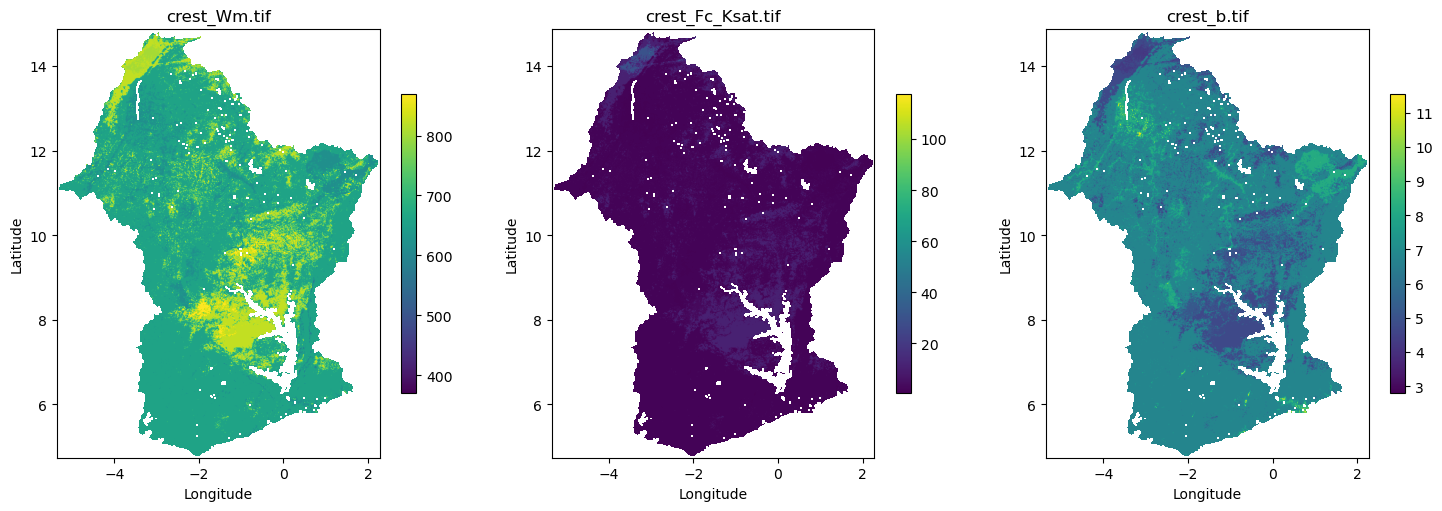

In [4]:
import rasterio
import matplotlib.pyplot as plt
from rasterio.enums import Resampling
from rasterio.plot import plotting_extent

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, (key, path) in zip(axes, outputs.items()):
    with rasterio.open(path) as src:
        # Limit display memory; parameter outputs retain their full resolution.
        scale = min(1.0, 1200 / max(src.height, src.width))
        data = src.read(
            1, masked=True,
            out_shape=(max(1, int(src.height * scale)), max(1, int(src.width * scale))),
            resampling=Resampling.nearest,
        )
        extent = plotting_extent(src)
        print(f"{path.name}: shape={src.shape}, CRS={src.crs}, tiled={src.is_tiled}, compression={src.compression}")
    image = ax.imshow(data, extent=extent, origin="upper")
    ax.set(title=path.name, xlabel="Longitude", ylabel="Latitude")
    fig.colorbar(image, ax=ax, shrink=0.7)
fig.tight_layout()
plt.show()


## Add the parameters to EF5

Copy these grid paths into your CREST parameter set.
Prepare the impervious layer `crest_IM.tif` separately in notebook 7b.


In [5]:
for setting, key in (("wm_grid", "wm"), ("fc_grid", "fc"), ("b_grid", "b")):
    print(f"{setting}={outputs[key]}")


wm_grid=/home/vrobledodelgado/LSS/Humberto/Vanessa/FF_climo/phase0_Building_models/EF5-builder-toolkit/Example/data_model/crest_parameters/crest_Wm.tif
fc_grid=/home/vrobledodelgado/LSS/Humberto/Vanessa/FF_climo/phase0_Building_models/EF5-builder-toolkit/Example/data_model/crest_parameters/crest_Fc_Ksat.tif
b_grid=/home/vrobledodelgado/LSS/Humberto/Vanessa/FF_climo/phase0_Building_models/EF5-builder-toolkit/Example/data_model/crest_parameters/crest_b.tif
